In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
data = load_breast_cancer()
X = data.data
y = data.target
print("Dataset Shape:", X.shape)
print("Target Classes:", data.target_names)

Dataset Shape: (569, 30)
Target Classes: ['malignant' 'benign']


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (455, 30)
Testing data shape: (114, 30)


In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training and testing features standardized.")

Training and testing features standardized.


In [5]:
model = LogisticRegression(max_iter=500)
start = time.time()
model.fit(X_train_scaled, y_train)
train_time_original = time.time() - start
pred_original = model.predict(X_test_scaled)
acc_original = accuracy_score(y_test, pred_original)
print("Original Features")
print("Accuracy:", round(acc_original, 4))
print("Training Time:", train_time_original)

Original Features
Accuracy: 0.9737
Training Time: 0.0318758487701416


In [6]:
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("Training data after PCA:", X_train_pca.shape)
print("Testing data after PCA:", X_test_pca.shape)

Training data after PCA: (455, 2)
Testing data after PCA: (114, 2)


In [7]:
model_pca = LogisticRegression(max_iter=500)
start = time.time()
model_pca.fit(X_train_pca, y_train)
train_time_pca = time.time() - start
pred_pca = model_pca.predict(X_test_pca)
acc_pca = accuracy_score(y_test, pred_pca)
print("PCA")
print("Accuracy:", round(acc_pca, 4))
print("Training Time:", train_time_pca)

PCA
Accuracy: 0.9912
Training Time: 0.002415180206298828


In [8]:
lda = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)
print("Training data after LDA:", X_train_lda.shape)
print("Testing data after LDA:", X_test_lda.shape)

Training data after LDA: (455, 1)
Testing data after LDA: (114, 1)


In [9]:
model_lda = LogisticRegression(max_iter=500)
start = time.time()
model_lda.fit(X_train_lda, y_train)
train_time_lda = time.time() - start
pred_lda = model_lda.predict(X_test_lda)
acc_lda = accuracy_score(y_test, pred_lda)
print("LDA")
print("Accuracy:", round(acc_lda, 4))
print("Training Time:", train_time_lda)

LDA
Accuracy: 0.9474
Training Time: 0.003231048583984375


In [10]:
results = pd.DataFrame({
    "Method": ["Original", "PCA", "LDA"],
    "Features": [X.shape[1], 2, 1],
    "Accuracy": [acc_original, acc_pca, acc_lda],
    "Training Time": [train_time_original, train_time_pca, train_time_lda]
})
display(results)

,Method,Features,Accuracy,Training Time
0,Original,30,0.973684,0.031876
1,PCA,2,0.991228,0.002415
2,LDA,1,0.947368,0.003231


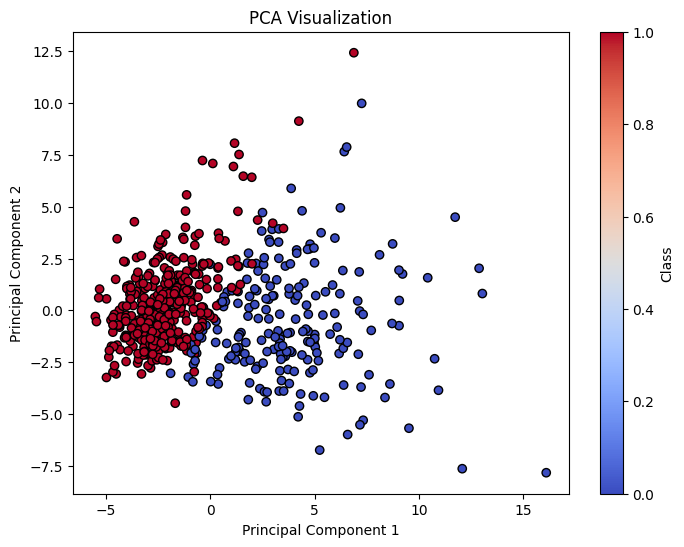

In [11]:
X_scaled_all = scaler.transform(X)
X_pca_all = pca.transform(X_scaled_all)
plt.figure(figsize=(8, 6))
plt.scatter(X_pca_all[:, 0], X_pca_all[:, 1], c=y, cmap="coolwarm", edgecolor="k")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")
plt.colorbar(label="Class")
plt.show()

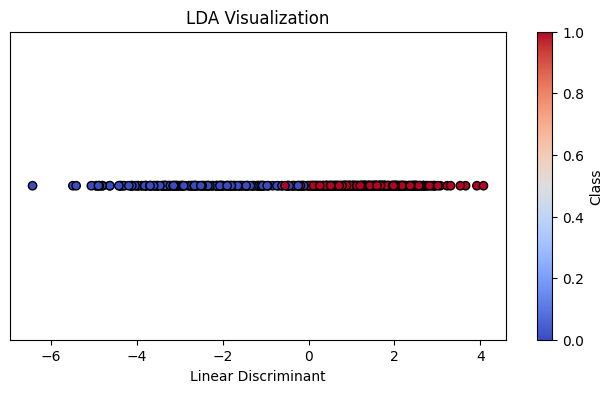

In [12]:
X_lda_all = lda.transform(X_scaled_all)
plt.figure(figsize=(8, 4))
plt.scatter(X_lda_all[:, 0], np.zeros_like(X_lda_all[:, 0]), c=y, cmap="coolwarm", edgecolors="k")
plt.yticks([])
plt.xlabel("Linear Discriminant")
plt.title("LDA Visualization")
plt.colorbar(label="Class")
plt.show()